In [1]:
import pandas as pd
import numpy as np
import joblib

raw = pd.read_csv("../data/Palo_Alto_Networks.csv")
raw.insert(0, "EmployeeID", range(1, len(raw) + 1))

df = raw.copy()
df["OverTime"] = df["OverTime"].map({"No": 0, "Yes": 1})
df["Gender"] = df["Gender"].map({"Female": 0, "Male": 1})
df = pd.get_dummies(
    df,
    columns=["BusinessTravel", "Department", "EducationField", "JobRole", "MaritalStatus"],
    dtype=int,
)

df["IncomeToExperience"] = df["MonthlyIncome"] / (df["TotalWorkingYears"] + 1)
df["PromotionDelay"] = df["YearsSinceLastPromotion"] / (df["YearsAtCompany"] + 1)
df["EngagementScore"] = df[
    ["JobSatisfaction", "EnvironmentSatisfaction", "RelationshipSatisfaction", "JobInvolvement"]
].mean(axis=1)
df["WorkloadStress"] = (
    (df["OverTime"] == 1) & (df["BusinessTravel_Travel_Frequently"] == 1)
).astype(int)

feature_cols = joblib.load("../models/feature_columns.pkl")
scaler = joblib.load("../models/scaler.pkl")

num_cols = [
    "Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome",
    "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears",
    "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
    "YearsSinceLastPromotion", "YearsWithCurrManager",
    "IncomeToExperience", "PromotionDelay", "EngagementScore",
]

X_all = df[feature_cols].copy()
X_all[num_cols] = scaler.transform(X_all[num_cols])
y_all = df["Attrition"]

print("X_all shape:", X_all.shape)
print("Columns match training:", list(X_all.columns) == feature_cols)
print("IncomeToExperience mean:", round(X_all["IncomeToExperience"].mean(), 2))

X_all shape: (1470, 53)
Columns match training: True
IncomeToExperience mean: -0.0


In [2]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

pipe = ImbPipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", LogisticRegression(max_iter=1000, random_state=42)),
])
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

prob = cross_val_predict(pipe, X_all, y_all, cv=cv, method="predict_proba")[:, 1]

scores = raw[["EmployeeID", "Department", "JobRole", "OverTime", "Attrition"]].copy()
scores["AttritionProbability"] = prob.round(3)
scores["RiskCategory"] = pd.cut(
    prob, bins=[-0.001, 0.30, 0.60, 1.0], labels=["Low", "Medium", "High"]
)

print(scores["RiskCategory"].value_counts())
print()
print("Actual attrition rate in each category (%):")
print((scores.groupby("RiskCategory", observed=True)["Attrition"].mean() * 100).round(1))

scores.to_csv("../data/processed/risk_scores.csv", index=False)

RiskCategory
Low       1158
Medium     209
High       103
Name: count, dtype: int64

Actual attrition rate in each category (%):
RiskCategory
Low        8.1
Medium    30.1
High      77.7
Name: Attrition, dtype: float64


Finding which factors drive the risk

Top factors that INCREASE leaving risk:
EngagementScore            3.90
OverTime                   1.44
YearsSinceLastPromotion    0.67
NumCompaniesWorked         0.44
DistanceFromHome           0.34
IncomeToExperience         0.33
WorkloadStress             0.16
Gender                     0.11
dtype: float64

Top factors that DECREASE leaving risk:
JobInvolvement              -2.41
EnvironmentSatisfaction     -2.33
JobSatisfaction             -2.28
RelationshipSatisfaction    -2.21
BusinessTravel_Non-Travel   -2.17
EducationField_Other        -2.13
MaritalStatus_Divorced      -1.96
EducationField_Medical      -1.88
dtype: float64


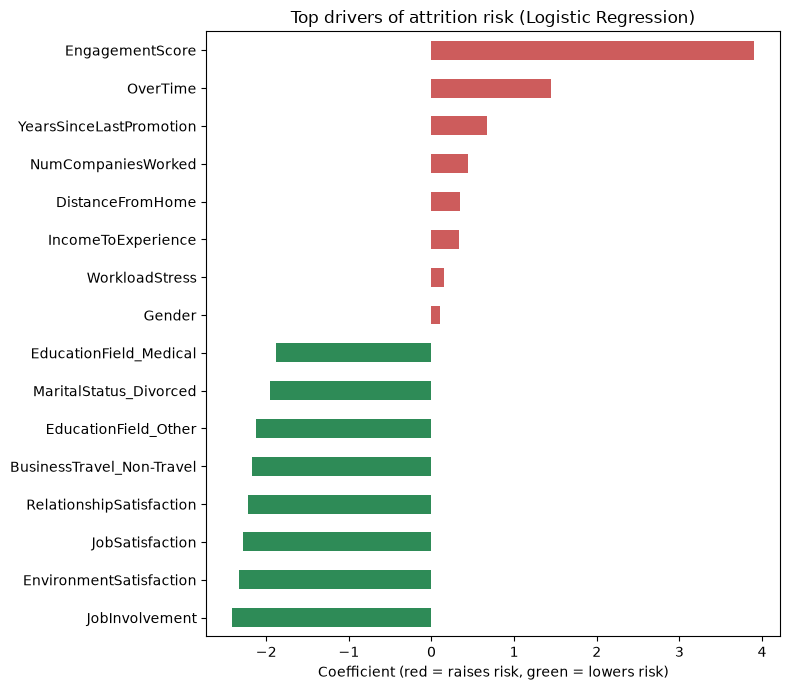

In [3]:
import matplotlib.pyplot as plt

lr_model = joblib.load("../models/logistic_regression.pkl")

coef = pd.Series(lr_model.coef_[0], index=feature_cols).sort_values()

print("Top factors that INCREASE leaving risk:")
print(coef.tail(8).iloc[::-1].round(2))
print()
print("Top factors that DECREASE leaving risk:")
print(coef.head(8).round(2))

top = pd.concat([coef.head(8), coef.tail(8)])
colors = ["seagreen" if v < 0 else "indianred" for v in top]
top.plot(kind="barh", figsize=(8, 7), color=colors)
plt.title("Top drivers of attrition risk (Logistic Regression)")
plt.xlabel("Coefficient (red = raises risk, green = lowers risk)")
plt.tight_layout()
plt.show()

Satisfaction & engagement    0.605
OverTime                     0.585
YearsSinceLastPromotion      0.491
Job role                     0.484
NumCompaniesWorked           0.367
Marital status               0.289
MonthlyIncome                0.277
DistanceFromHome             0.274
StockOptionLevel             0.271
YearsWithCurrManager         0.265
dtype: float64


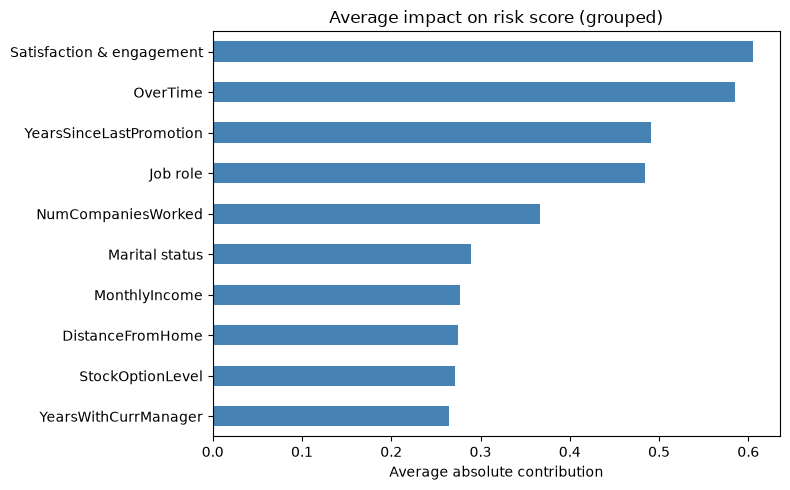

In [4]:
coef = pd.Series(lr_model.coef_[0], index=feature_cols)
contrib = (X_all[feature_cols] - X_all[feature_cols].mean()) * coef

groups = {
    "Satisfaction & engagement": ["JobInvolvement", "EnvironmentSatisfaction",
                                  "JobSatisfaction", "RelationshipSatisfaction",
                                  "EngagementScore"],
    "Business travel & workload stress": [c for c in feature_cols if c.startswith("BusinessTravel_")] + ["WorkloadStress"],
    "Job role": [c for c in feature_cols if c.startswith("JobRole_")],
    "Marital status": [c for c in feature_cols if c.startswith("MaritalStatus_")],
    "Department": [c for c in feature_cols if c.startswith("Department_")],
    "Education field": [c for c in feature_cols if c.startswith("EducationField_")],
}

grouped = pd.DataFrame(index=contrib.index)
used = []
for name, cols in groups.items():
    grouped[name] = contrib[cols].sum(axis=1)
    used += cols
for c in feature_cols:
    if c not in used:
        grouped[c] = contrib[c]

importance = grouped.abs().mean().sort_values(ascending=False)
print(importance.head(10).round(3))

importance.head(10)[::-1].plot(kind="barh", figsize=(8, 5), color="steelblue")
plt.title("Average impact on risk score (grouped)")
plt.xlabel("Average absolute contribution")
plt.tight_layout()
plt.show()

Creating plain-English reason codes for each employee

In [5]:
labels = {
    "Satisfaction & engagement": "Low satisfaction and engagement",
    "Business travel & workload stress": "Frequent travel / workload stress",
    "Job role": "High-turnover job role",
    "Marital status": "Marital status (single)",
    "Department": "Department",
    "Education field": "Education field",
    "OverTime": "Works overtime",
    "YearsSinceLastPromotion": "Long time since last promotion",
    "NumCompaniesWorked": "Many previous employers",
    "DistanceFromHome": "Long commute",
    "MonthlyIncome": "Low monthly income",
    "StockOptionLevel": "Low stock option level",
    "YearsWithCurrManager": "Few years with current manager",
    "TotalWorkingYears": "Little total experience",
    "Age": "Younger age",
    "JobLevel": "Low job level",
    "YearsInCurrentRole": "Few years in current role",
    "YearsAtCompany": "Few years at company",
    "PromotionDelay": "Promotion delay",
    "IncomeToExperience": "Income vs experience mismatch",
}

reasons = []
for i in grouped.index:
    row = grouped.loc[i]
    top = row[row > 0].sort_values(ascending=False).head(3)
    reasons.append(" + ".join(
        labels.get(k, ("Higher " if coef.get(k, 1) > 0 else "Lower ") + k)
        for k in top.index
    ))

scores["TopReasons"] = reasons
scores.to_csv("../data/processed/risk_scores.csv", index=False)

high = scores[scores["RiskCategory"] == "High"].sort_values("AttritionProbability", ascending=False)
print(high[["EmployeeID", "JobRole", "AttritionProbability", "TopReasons"]].head(8).to_string(index=False))

 EmployeeID               JobRole  AttritionProbability                                                                                  TopReasons
        464 Laboratory Technician                 0.986                      Works overtime + Lower WorkLifeBalance + Income vs experience mismatch
        458  Sales Representative                 0.983                     Income vs experience mismatch + Works overtime + High-turnover job role
        358  Sales Representative                 0.980                   Low satisfaction and engagement + Works overtime + High-turnover job role
       1061 Laboratory Technician                 0.964        Works overtime + Frequent travel / workload stress + Low satisfaction and engagement
        690 Laboratory Technician                 0.949    Low satisfaction and engagement + Income vs experience mismatch + High-turnover job role
        128  Sales Representative                 0.942                     Income vs experience mismatch + Work